# 데이터 살펴보기

모델을 만들기 전에 어떤 데이터가 있는지, 얼마나 있는지, 어떻게 생겼는지 확인함.

1. 무엇이 들어 있나
2. 정상과 불량
3. 결함 유형과 면적
4. 정상끼리도 얼마나 다른가
5. train 과 val
6. 신호가 있는지 확인

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'example' else Path.cwd()))
warnings.filterwarnings('ignore')
_ko = [f for f in ['NanumGothic', 'Noto Sans CJK KR', 'Noto Serif CJK KR', 'AppleGothic', 'Malgun Gothic']
       if any(f == x.name for x in font_manager.fontManager.ttflist)]
plt.rcParams['font.family'] = _ko[:1] + ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

from src import Dataset

ds = Dataset()
ds

Dataset(dataset/: 38개 카테고리, 47,403 장)

## 1. 무엇이 들어 있나

`index.csv` 한 줄이 이미지 한 장임. 5개 도메인, 38개 카테고리가 있음.

In [14]:
for group, cats in ds.domains.items():
    print(f'{group:12} {len(cats):2}개  {", ".join(cats)}')

agriculture   4개  agri_01, agri_02, agri_03, agri_04
electronics  11개  elec_01, elec_02, elec_03, elec_04, elec_05, elec_06, elec_07, elec_08, elec_09, elec_10, elec_11
groceries     3개  groc_01, groc_02, groc_03
mechanics    11개  mech_01, mech_02, mech_03, mech_04, mech_05, mech_06, mech_07, mech_08, mech_09, mech_10, mech_11
medicine      9개  med_01, med_02, med_03, med_04, med_05, med_06, med_07, med_08, med_09


In [3]:
ds.index.head(3)

,group,category,split,label,path,mask_path,mask_area_pct,is_anomaly
0,agriculture,agri_01,train,good,agriculture/agri_01/train/good/0001.png,,0.0,0
1,agriculture,agri_01,train,good,agriculture/agri_01/train/good/0002.png,,0.0,0
2,agriculture,agri_01,train,good,agriculture/agri_01/train/good/0003.png,,0.0,0


In [4]:
t = ds.index
count = (t.assign(kind=np.where(t.split == 'train', 'train',
                                np.where(t.label == 'good', 'val_good', 'val_bad')))
           .groupby(['group', 'category', 'kind']).size()
           .unstack(fill_value=0)[['train', 'val_good', 'val_bad']])
count

kind                  train  val_good  val_bad
group       category                          
agriculture agri_01    1000       100       50
            agri_02    1000       100       49
            agri_03    1000       100       49
            agri_04    1000       100       50
electronics elec_01    1366        39       20
            elec_02    1390        35       17
            elec_03    1120        80       40
            elec_04    1180        70       35
            elec_05    1240        60       29
            elec_06    1000       100       48
            elec_07    1102        83       42
            elec_08    1324        46       21
            elec_09    1324        46       22
            elec_10    1348        42       21
            elec_11    1096        84       43
groceries   groc_01    1000       100       49
            groc_02    1000       100       49
            groc_03    1000       100       52
mechanics   mech_01    1168        72       36
            mech_02    1000       100       46
            mech_03    1156        74       36
            mech_04    1156        74       37
            mech_05    1402        33       13
            mech_06    1462        23        9
            mech_07    1114        81       42
            mech_08    1102        83       41
            mech_09    1000       100       50
            mech_10    1000       100       49
            mech_11    1066        89       43
medicine    med_01     1012        98       47
            med_02     1078        87       43
            med_03     1280        51       30
            med_04     1000       100       50
            med_05     1054        91       44
            med_06     1222        63       32
            med_07     1186        69       35
            med_08     1000       100       49
            med_09     1018        97       49

학습용 정상은 카테고리당 1,000~1,460장, val 불량은 9~52장으로 차이가 큼.
불량이 적은 카테고리는 몇 장에 따라 AUROC 가 크게 흔들림.

## 2. 정상과 불량

카테고리 하나를 잡아 정상과 불량을 나란히 봄. 정답 마스크는 결함 픽셀만 1 임.

In [5]:
cat = ds.category('agri_02')
cat

Category(agri_02: train 1000 / val 149 장 (불량 49) / test 0 장)

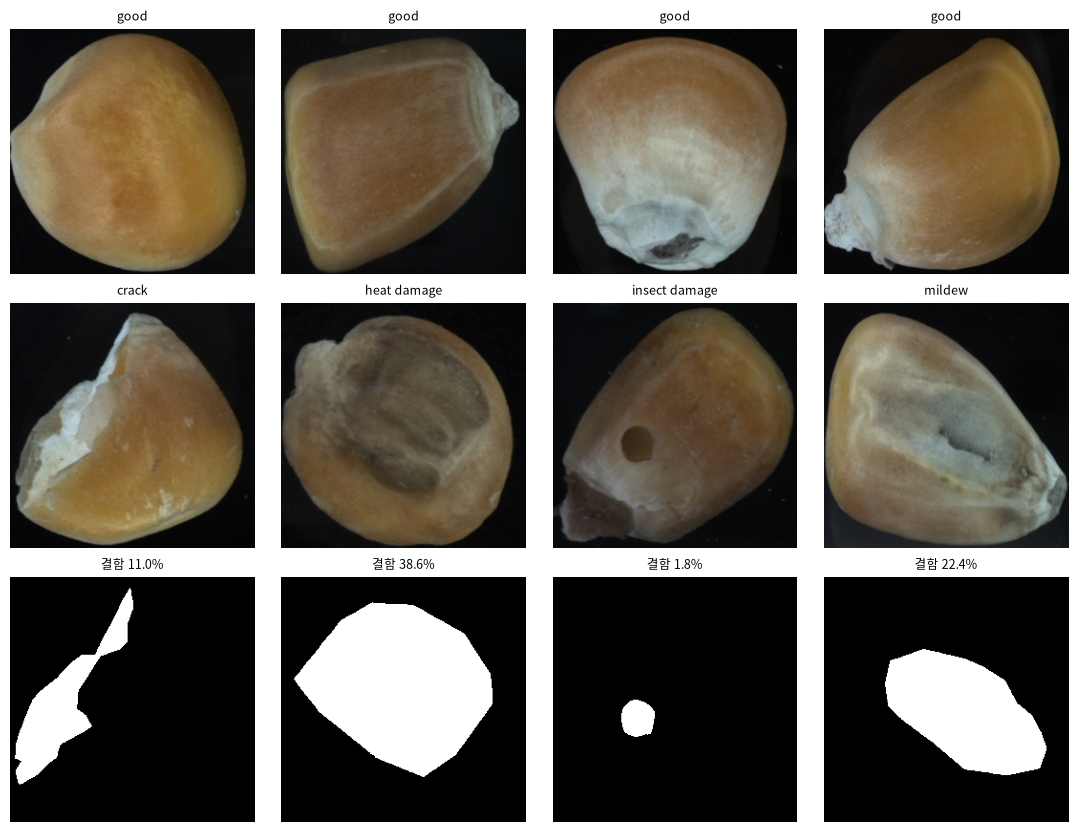

In [6]:
t = cat.val
good = t[t.is_anomaly == 0].head(4)
bad = t[t.is_anomaly == 1].groupby('label').head(1).head(4)

fig, ax = plt.subplots(3, 4, figsize=(11, 8.4))
for j, x in enumerate(cat.images(good)):
    ax[0, j].imshow(x); ax[0, j].set_title('good', fontsize=9)
x, m = cat.images(bad), cat.masks(bad)
for j in range(len(bad)):
    ax[1, j].imshow(x[j]); ax[1, j].set_title(bad.label.iloc[j], fontsize=9)
    ax[2, j].imshow(m[j], cmap='gray')
    ax[2, j].set_title(f'결함 {bad.mask_area_pct.iloc[j]:.1f}%', fontsize=9)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 3. 결함 유형과 면적

결함 유형은 `label` 열에 있음. 카테고리마다 다름.

In [7]:
bad = ds.index[ds.index.is_anomaly == 1]
types = bad.groupby(['category', 'label']).size().rename('장 수').reset_index()
types[types.category.isin(['agri_02', 'med_08', 'mech_07', 'elec_10', 'groc_01'])] \
    .pivot(index='category', columns='label', values='장 수').fillna(0).astype(int)

label,black bean,broken bean,compression,crack,double cap,fragmentation,heat damage,indentation,insect damage,mildew,mold,moldy bean,multi_anomalies,peaberry,scratch,spot,sprouting,stain,take-all
category,,,,,,,,,,,,,,,,,,,
agri_02,0,0,0,6,0,0,4,0,10,9,4,0,7,0,0,5,4,0,0
elec_10,0,0,0,0,0,8,0,0,0,0,0,0,4,0,2,0,0,7,0
groc_01,8,11,0,0,0,0,0,0,1,0,0,12,0,7,0,0,0,0,10
mech_07,0,0,0,0,0,12,0,0,0,0,0,0,12,0,6,0,0,12,0
med_08,0,0,14,0,19,1,0,9,0,0,0,0,4,0,0,0,0,2,0


### 결함 면적

이미지에서 결함이 차지하는 면적은 대부분 몇 % 에 불과함. 평가에서 소(<1%) / 중(1~5%) / 대(>5%)
로 나눠서 따로 봄. **작은 결함이 훨씬 어려움.**

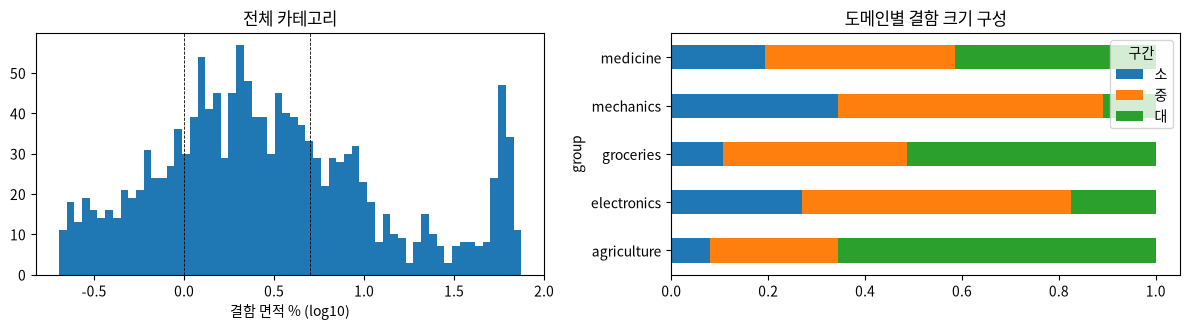

In [8]:
from src import SIZE_BINS

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(np.log10(bad.mask_area_pct), bins=60)
ax[0].set_xlabel('결함 면적 % (log10)'); ax[0].set_title('전체 카테고리')
for lo, hi, name in SIZE_BINS[:-1]:
    ax[0].axvline(np.log10(hi), color='k', lw=0.6, ls='--')

share = (bad.assign(구간=pd.cut(bad.mask_area_pct, [b[0] for b in SIZE_BINS] + [100],
                               labels=[b[2] for b in SIZE_BINS]))
            .groupby('group').구간.value_counts(normalize=True).unstack())
share.plot.barh(stacked=True, ax=ax[1]); ax[1].set_title('도메인별 결함 크기 구성')
plt.tight_layout(); plt.show()

In [9]:
bad.groupby('category').mask_area_pct.median().sort_values().round(1).to_frame('결함 면적 중앙값 %').T

category,elec_01,mech_05,mech_11,elec_03,mech_02,elec_05,elec_06,elec_10,mech_08,mech_10,...,elec_08,elec_09,groc_02,agri_01,agri_04,agri_02,agri_03,groc_01,med_08,med_04
결함 면적 중앙값 %,0.8,0.9,0.9,1.0,1.1,1.3,1.3,1.4,1.4,1.4,...,3.4,4.0,4.3,4.5,6.9,20.2,20.8,21.0,55.7,58.8


카테고리마다 결함 크기가 아주 다름. 큰 결함이 많은 카테고리는 쉽고, 작은 결함이 많은 카테고리는
어려움. 제출하는 방법 하나가 이 차이를 모두 견뎌야 함.

## 4. 정상끼리도 얼마나 다른가

정상 개체끼리의 차이가 크면 이상과 정상을 가르기가 어려워짐. 곡물은 알갱이마다 모양이
제각각이고 전자부품은 규격이 일정함. 놓인 자세도 이미지마다 다름.

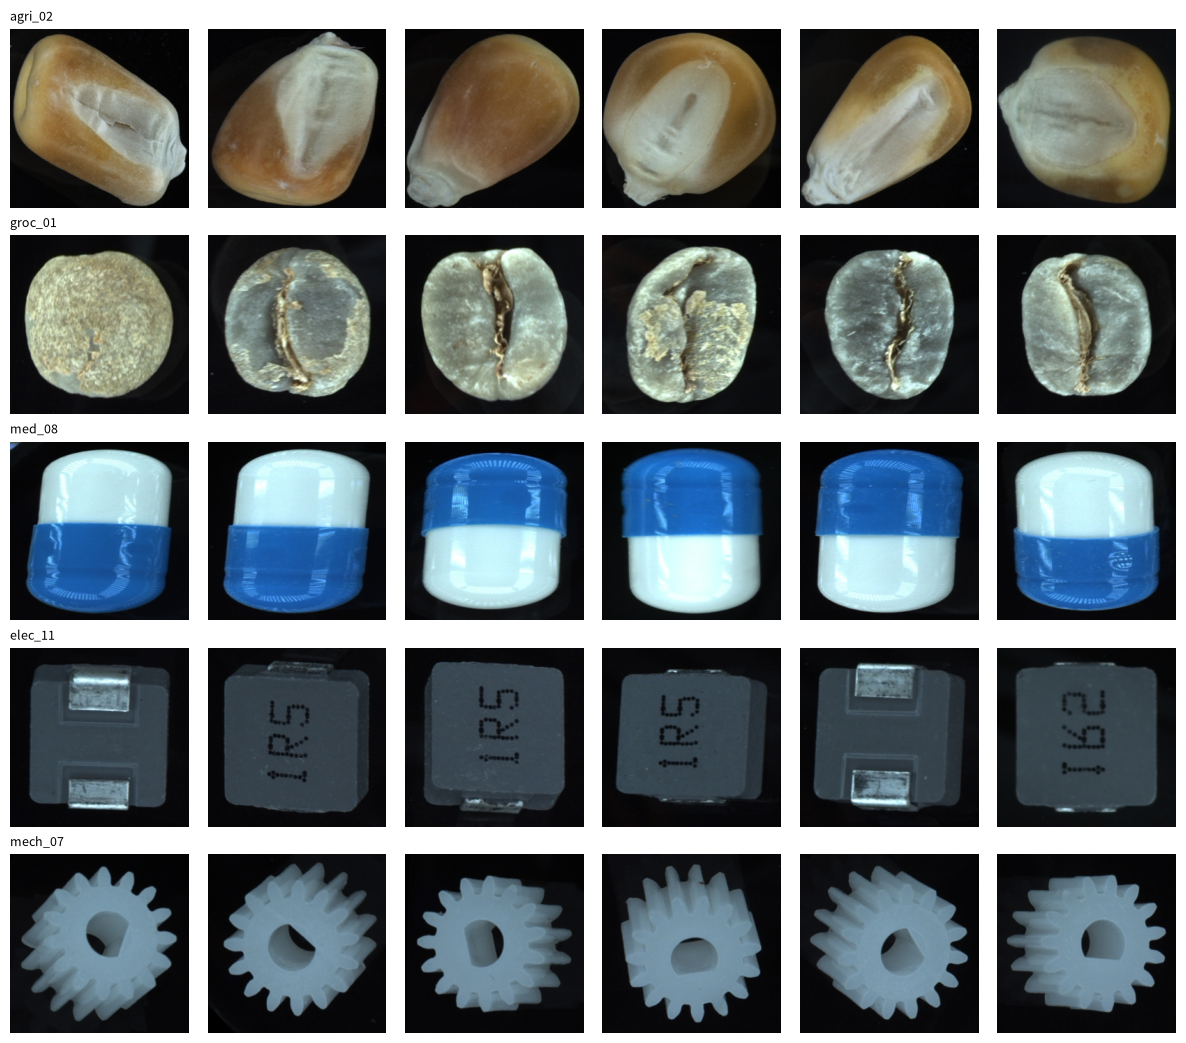

In [10]:
show = ['agri_02', 'groc_01', 'med_08', 'elec_11', 'mech_07']
fig, ax = plt.subplots(len(show), 6, figsize=(12, 2.1 * len(show)))
for r, name in enumerate(show):
    c = ds.category(name)
    x = c.images(c.train.sample(6, random_state=0))
    for j in range(6):
        ax[r, j].imshow(x[j]); ax[r, j].axis('off')
    ax[r, 0].set_title(name, fontsize=9, loc='left')
plt.tight_layout(); plt.show()

배경이 검고 물체가 가운데 놓인 구조임. 물체 밖의 배경은 정상이든 불량이든 똑같음.
이걸 어떻게 다룰지도 모델을 만들 때 판단할 지점임.

## 5. train 과 val

- `train` — `fit` 에 넣음. **정상만**
- `val` — 정상과 불량. 모델을 고르고, 임계값을 정하고, 해석을 검증하는 데 씀.
  **정상이든 불량이든 학습에는 쓰지 않음**
- 채점은 따로 떼어 둔 비공개 test 로 함. val 과 같은 구성임

In [11]:
print(cat.summary())
print('train / val 의 불량:', int(cat.train.is_anomaly.sum()), '/', int(cat.val.is_anomaly.sum()))

{'category': 'agri_02', 'train': 1000, 'val_normal': 100, 'val_anomalous': 49, 'defect_types': 8, 'test': 0}
train / val 의 불량: 0 / 49


## 6. 신호가 있는지 확인

가장 단순한 것부터 봄. 정상 이미지의 **평균 영상**에서 얼마나 먼지를 점수로 씀.
위치도 질감도 보지 않음.

In [12]:
from src import baselines

for name in ['agri_02', 'med_08', 'elec_11']:
    print(name)
    print(baselines(ds.category(name)).to_string(index=False), '\n')

agri_02


    기준선  image_auroc
 무작위 점수     0.462041
평균영상 거리     0.550816 

med_08
    기준선  image_auroc
 무작위 점수     0.525306
평균영상 거리     0.566327 

elec_11
    기준선  image_auroc
 무작위 점수     0.508306
평균영상 거리     0.604097 



평균영상 거리는 0.5 를 조금 넘는 정도임. 이미지 전체를 한 덩어리로 비교하면 결함이
정상 개체끼리의 차이에 묻힘. **위치마다 따로 비교**해야 함.

결함 부위와 정상 부위의 값이 실제로 다른지 봄.

In [13]:
from src.features import patch_stats

rows = cat.val[cat.val.is_anomaly == 1].head(60)
f = patch_stats(cat.images(rows))               # (n, 32, 32, 8)
m = cat.masks(rows).reshape(len(rows), 32, 8, 32, 8).mean(axis=(2, 4)) > 0.5

names = ['R', 'G', 'B', 'R sd', 'G sd', 'B sd', 'grad', 'grad sd']
fg = f[..., :3].mean(-1) > 0.12               # 물체가 있는 칸
pd.DataFrame({'결함 칸': f[m].mean(0), '정상 칸(물체 위)': f[~m & fg].mean(0)},
             index=names).round(3).T

,R,G,B,R sd,G sd,B sd,grad,grad sd
결함 칸,0.451,0.455,0.404,0.033,0.035,0.038,0.038,0.023
정상 칸(물체 위),0.445,0.402,0.305,0.033,0.035,0.034,0.034,0.024


결함 칸은 색이나 질감이 정상 칸과 다름. 칸 단위로 보면 신호가 있다는 뜻임.
`2_modeling.ipynb` 에서 이걸로 모델을 만듦.